# Prosperity 4 — tutorial round backtester

Two separate strategies for two fundamentally different instruments:
- **EmeraldStrategy** — pure market making around a fixed fair value
- **TomatoStrategy** — asymmetric quoting driven by a ridge-regression signal

Sections:
1. Imports
2. File paths
3. Data loading & exploration
4. Datamodel
5. Feature engineering
6. Feature analysis (correlations + collinearity)
7. Ridge regression signal
8. EmeraldStrategy
9. TomatoStrategy
10. Trader (routes to the right strategy)
11. Backtester
12. Run & compare
13. PnL plot
14. Parameter sweep


## 1. Imports

In [1]:
import csv
from collections import defaultdict
from dataclasses import dataclass, field
from typing import Dict, List, Optional
import statistics

try:
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mtick
    HAS_MPL = True
except ImportError:
    HAS_MPL = False
    print("matplotlib not found — plots will be skipped")


## 2. File paths

In [2]:
PRICE_FILES = [
    "prices_round_0_day_-1.csv",
    "prices_round_0_day_-2.csv",
]
TRADE_FILES = [
    "trades_round_0_day_-1.csv",
    "trades_round_0_day_-2.csv",
]

POSITION_LIMITS = {"EMERALDS": 80, "TOMATOES": 80}


## 3. Data loading & exploration

In [3]:
def load_prices(path: str) -> dict:
    """Returns {timestamp: {product: {bids, asks, mid}}}."""
    data = defaultdict(dict)
    with open(path) as f:
        for row in csv.DictReader(f, delimiter=";"):
            ts, prd = int(row["timestamp"]), row["product"]
            bids, asks = [], []
            for i in (1, 2, 3):
                bp = row.get(f"bid_price_{i}", "").strip()
                bv = row.get(f"bid_volume_{i}", "").strip()
                ap = row.get(f"ask_price_{i}", "").strip()
                av = row.get(f"ask_volume_{i}", "").strip()
                if bp and bv: bids.append((int(float(bp)), int(float(bv))))
                if ap and av: asks.append((int(float(ap)), int(float(av))))
            bids.sort(key=lambda x: -x[0])
            asks.sort(key=lambda x:  x[0])
            data[ts][prd] = {
                "bids": bids, "asks": asks,
                "mid":  float(row["mid_price"]) if row.get("mid_price") else None,
            }
    return data


def load_trades(path: str) -> dict:
    """Returns {timestamp: [{symbol, price, quantity}]}."""
    data = defaultdict(list)
    with open(path) as f:
        for row in csv.DictReader(f, delimiter=";"):
            ts  = int(row["timestamp"])
            sym = row.get("symbol", row.get("product", ""))
            data[ts].append({
                "symbol":   sym,
                "price":    float(row["price"]),
                "quantity": int(float(row["quantity"])),
            })
    return data


# Load & summarise
from itertools import chain

all_prices = {pf: load_prices(pf) for pf in PRICE_FILES}
all_trades = {tf: load_trades(tf) for tf in TRADE_FILES}
price_rows = list(chain.from_iterable(d.values() for d in all_prices.values()))

print(f"Loaded {len(PRICE_FILES)} days\n")
for product in POSITION_LIMITS:
    mids    = [ts[product]["mid"] for ts in price_rows
               if product in ts and ts[product]["mid"]]
    spreads = [ts[product]["asks"][0][0] - ts[product]["bids"][0][0]
               for ts in price_rows
               if product in ts and ts[product]["bids"] and ts[product]["asks"]]
    print(f"{product}")
    print(f"  mid  — mean: {statistics.mean(mids):>8.1f}  "
          f"stdev: {statistics.stdev(mids):>5.1f}  "
          f"min: {min(mids):.1f}  max: {max(mids):.1f}")
    print(f"  spread — mean: {statistics.mean(spreads):.1f}  "
          f"min: {min(spreads)}  max: {max(spreads)}")
    print()


Loaded 2 days

EMERALDS
  mid  — mean:  10000.0  stdev:   0.7  min: 9996.0  max: 10004.0
  spread — mean: 15.7  min: 8  max: 16

TOMATOES
  mid  — mean:   4992.8  stdev:  19.7  min: 4946.5  max: 5036.0
  spread — mean: 13.0  min: 5  max: 14



## 4. Datamodel

In [4]:
@dataclass
class Order:
    symbol:   str
    price:    int
    quantity: int   # positive = buy, negative = sell

    def __repr__(self):
        side = "BUY" if self.quantity > 0 else "SELL"
        return f"Order({self.symbol} {side} {abs(self.quantity)}@{self.price})"


@dataclass
class OrderDepth:
    buy_orders:  Dict[int, int] = field(default_factory=dict)
    sell_orders: Dict[int, int] = field(default_factory=dict)

    @property
    def best_bid(self): return max(self.buy_orders)  if self.buy_orders  else None
    @property
    def best_ask(self): return min(self.sell_orders) if self.sell_orders else None
    @property
    def mid(self):
        return (self.best_bid + self.best_ask) / 2                if self.best_bid is not None and self.best_ask is not None else None
    @property
    def spread(self):
        return self.best_ask - self.best_bid                if self.best_bid is not None and self.best_ask is not None else None


class TradingState:
    def __init__(self, traderData, timestamp, order_depths,
                 own_trades, market_trades, position, observations=None):
        self.traderData    = traderData
        self.timestamp     = timestamp
        self.order_depths  = order_depths
        self.own_trades    = own_trades
        self.market_trades = market_trades
        self.position      = position
        self.observations  = observations or {}
        self.listings      = {}


def build_order_depth(book: dict) -> OrderDepth:
    od = OrderDepth()
    for px, vol in book["bids"]: od.buy_orders[px]  =  vol
    for px, vol in book["asks"]: od.sell_orders[px] = -vol
    return od


## 5. Trend signal analysis

Before tuning, verify the EMA trend signal actually tracks the daily direction.
`FAST_ALPHA=0.18` reacts over ~5 ticks; `SLOW_ALPHA=0.04` anchors over ~25 ticks.
`trend = emaFast - emaSlow` is positive in uptrends, negative in downtrends.


In [5]:
FAST_ALPHA = 0.18
SLOW_ALPHA = 0.04
TREND_THRESHOLD = 0.75   # ticks above/below zero that trigger asymmetric sizing

def analyse_trend(price_file, product="TOMATOES"):
    prices   = load_prices(price_file)
    emaFast  = emaSlow = None
    triggers = {"down": 0, "up": 0, "neutral": 0}
    trend_series = []

    for ts in sorted(prices):
        if product not in prices[ts]: continue
        mid = prices[ts][product]["mid"]
        if mid is None: continue
        if emaFast is None:
            emaFast = emaSlow = mid
        else:
            emaFast = FAST_ALPHA * mid + (1 - FAST_ALPHA) * emaFast
            emaSlow = SLOW_ALPHA * mid + (1 - SLOW_ALPHA) * emaSlow
        trend = emaFast - emaSlow
        trend_series.append(trend)
        if   trend < -TREND_THRESHOLD: triggers["down"]    += 1
        elif trend >  TREND_THRESHOLD: triggers["up"]      += 1
        else:                          triggers["neutral"]  += 1

    n = len(trend_series)
    print(f"{price_file.split('/')[-1]}  {product}")
    print(f"  cut bids   (trend < -{TREND_THRESHOLD}): {triggers['down']:>5}  {100*triggers['down']/n:.1f}%")
    print(f"  cut asks   (trend > +{TREND_THRESHOLD}): {triggers['up']:>5}  {100*triggers['up']/n:.1f}%")
    print(f"  neutral:                          {triggers['neutral']:>5}  {100*triggers['neutral']/n:.1f}%")
    print(f"  mean trend: {sum(trend_series)/n:+.3f}   "
          f"min: {min(trend_series):+.3f}   max: {max(trend_series):+.3f}")
    print()

for pf in PRICE_FILES:
    analyse_trend(pf)


prices_round_0_day_-1.csv  TOMATOES
  cut bids   (trend < -0.75):  3165  31.6%
  cut asks   (trend > +0.75):  2554  25.5%
  neutral:                           4281  42.8%
  mean trend: -0.102   min: -4.603   max: +4.420

prices_round_0_day_-2.csv  TOMATOES
  cut bids   (trend < -0.75):  2643  26.4%
  cut asks   (trend > +0.75):  2814  28.1%
  neutral:                           4543  45.4%
  mean trend: +0.018   min: -4.225   max: +3.513



## 6. EmeraldStrategy

Fixed fair value of 10,000. Pure symmetric market making:
- Quote `fair ± HALF_SPREAD` inside the bot spread (bots quote ±8)
- Inventory skew shifts both quotes to lean against accumulation
- Aggressive leg takes any bot order that crosses fair value
- Best parameters from sweep: `HALF_SPREAD=4, SKEW_MAX=2`


In [6]:
class EmeraldStrategy:
    FAIR_VALUE  = 10_000
    LIMIT       = 80
    HALF_SPREAD = 4      # ticks inside the bot ±8 spread
    SKEW_MAX    = 2      # max quote shift at position limit

    def _skew(self, pos: int) -> int:
        return round((pos / self.LIMIT) * self.SKEW_MAX)

    def orders(self, od: OrderDepth, pos: int) -> List[Order]:
        if od.best_bid is None or od.best_ask is None:
            return []
        skew  = self._skew(pos)
        bidPx = self.FAIR_VALUE - self.HALF_SPREAD - skew
        askPx = self.FAIR_VALUE + self.HALF_SPREAD - skew
        result = []

        # Aggressive: take any bot order that crosses fair value
        for askPxBook in sorted(od.sell_orders):
            if askPxBook > self.FAIR_VALUE: break
            vol = min(-od.sell_orders[askPxBook], self.LIMIT - pos)
            if vol > 0:
                result.append(Order("EMERALDS", askPxBook, vol))
                pos += vol

        for bidPxBook in sorted(od.buy_orders, reverse=True):
            if bidPxBook < self.FAIR_VALUE: break
            vol = min(od.buy_orders[bidPxBook], self.LIMIT + pos)
            if vol > 0:
                result.append(Order("EMERALDS", bidPxBook, -vol))
                pos -= vol

        # Passive: rest quotes inside the bot spread
        buyCap  = max(0, self.LIMIT - pos)
        sellCap = max(0, self.LIMIT + pos)
        if buyCap  > 0: result.append(Order("EMERALDS", bidPx,  buyCap))
        if sellCap > 0: result.append(Order("EMERALDS", askPx, -sellCap))
        return result


## 7. TomatoStrategy

Tomatoes have a drifting fair value. Strategy has three layers:

1. **Fair value**: `emaSlow + TREND_FAIR_WEIGHT * trend` — anchors to the slow
   EMA but tilts toward momentum, so quotes follow the trend rather than fight it
2. **Dynamic spread**: widens when z-score is extreme (price stretched from mean),
   narrowing when near-mean to collect more spread income
3. **Asymmetric sizing**: cuts bid capacity in downtrends, ask capacity in uptrends.
   Also allows a small fade when price is at extreme z-score dislocations.

Best parameters from sweep: `BASE_HALF_SPREAD=5, TREND_FAIR_WEIGHT=1.2`


In [7]:
class TomatoStrategy:
    LIMIT             = 40      # smaller than emeralds — tomatoes are riskier
    BASE_HALF_SPREAD  = 5       # best from sweep (wider = more margin per fill)
    SKEW_MAX          = 2       # inventory skew
    FAST_ALPHA        = 0.18    # ~5-tick EMA
    SLOW_ALPHA        = 0.04    # ~25-tick EMA
    Z_WINDOW          = 80      # rolling window for z-score baseline
    TREND_FAIR_WEIGHT = 1.2     # best from sweep (>1 = momentum-following fair value)
    EXTREME_Z         = 1.5     # z-score beyond which we allow a small mean-reversion fade

    def __init__(self):
        self.emaFast = None
        self.emaSlow = None
        self.midHist = []

    def _updateSignals(self, mid: float):
        if self.emaFast is None:
            self.emaFast = mid
            self.emaSlow = mid
        else:
            self.emaFast = self.FAST_ALPHA * mid + (1 - self.FAST_ALPHA) * self.emaFast
            self.emaSlow = self.SLOW_ALPHA * mid + (1 - self.SLOW_ALPHA) * self.emaSlow
        self.midHist.append(mid)
        if len(self.midHist) > self.Z_WINDOW:
            self.midHist.pop(0)
        meanMid = sum(self.midHist) / len(self.midHist)
        stdMid  = (sum((x - meanMid) ** 2 for x in self.midHist) / len(self.midHist)) ** 0.5
        zScore  = (mid - meanMid) / stdMid if stdMid > 1e-9 else 0.0
        trend   = self.emaFast - self.emaSlow
        return trend, zScore, meanMid

    def _skew(self, pos: int) -> int:
        return round((pos / self.LIMIT) * self.SKEW_MAX)

    def orders(self, od: OrderDepth, pos: int) -> List[Order]:
        if od.best_bid is None or od.best_ask is None:
            return []
        mid = od.mid
        trend, zScore, meanMid = self._updateSignals(mid)

        # Fair value: slow anchor + trend tilt
        fair       = self.emaSlow + self.TREND_FAIR_WEIGHT * trend
        # Spread widens when price is stretched from its rolling mean
        halfSpread = self.BASE_HALF_SPREAD + int(min(3, abs(zScore)))
        skew       = self._skew(pos)
        bidPx      = round(fair - halfSpread - skew)
        askPx      = round(fair + halfSpread - skew)

        # Asymmetric sizing: lean with the trend
        buyCap  = self.LIMIT - pos
        sellCap = self.LIMIT + pos
        if trend < -0.75:
            buyCap  = round(0.25 * buyCap)    # downtrend: cut bids hard
        elif trend > 0.75:
            sellCap = round(0.25 * sellCap)   # uptrend: cut asks hard

        # Allow a small fade at extreme dislocations (mean reversion safety valve)
        if zScore < -self.EXTREME_Z:
            buyCap  = max(buyCap,  round(0.35 * (self.LIMIT - pos)))
        elif zScore > self.EXTREME_Z:
            sellCap = max(sellCap, round(0.35 * (self.LIMIT + pos)))

        result = []

        # Aggressive: take bot orders clearly better than fair value
        for askPxBook in sorted(od.sell_orders):
            if askPxBook > fair - 1: break
            vol = min(-od.sell_orders[askPxBook], self.LIMIT - pos)
            if vol > 0:
                result.append(Order("TOMATOES", askPxBook, vol))
                pos += vol

        for bidPxBook in sorted(od.buy_orders, reverse=True):
            if bidPxBook < fair + 1: break
            vol = min(od.buy_orders[bidPxBook], self.LIMIT + pos)
            if vol > 0:
                result.append(Order("TOMATOES", bidPxBook, -vol))
                pos -= vol

        # Passive: rest quotes with asymmetric sizing
        buyCap  = max(0, min(buyCap,  self.LIMIT - pos))
        sellCap = max(0, min(sellCap, self.LIMIT + pos))
        if buyCap  > 0: result.append(Order("TOMATOES", bidPx,  buyCap))
        if sellCap > 0: result.append(Order("TOMATOES", askPx, -sellCap))
        return result


## 8. Trader

Thin routing layer. This is what gets uploaded to the platform — just copy
`EmeraldStrategy`, `TomatoStrategy`, and `Trader` into `trader.py`.


In [8]:
class Trader:
    def __init__(self):
        self._emerald = EmeraldStrategy()
        self._tomato  = TomatoStrategy()

    def run(self, state: TradingState):
        result = {}
        if "EMERALDS" in state.order_depths:
            result["EMERALDS"] = self._emerald.orders(
                state.order_depths["EMERALDS"],
                state.position.get("EMERALDS", 0))
        if "TOMATOES" in state.order_depths:
            result["TOMATOES"] = self._tomato.orders(
                state.order_depths["TOMATOES"],
                state.position.get("TOMATOES", 0))
        return result, 0, ""


## 9. Backtester

Simulates two fill types:
- **Aggressive**: our order price crosses a bot quote → instant fill at bot price
- **Passive**: a bot market trade occurs at or through our resting quote → we get filled

Returns a dict with `totalPnl`, `realized`, `mtm`, `pnlByProduct`,
`numTrades`, `endPositions`, and `pnl_curve`.


In [9]:
def run_backtest(trader, price_files=PRICE_FILES, trade_files=TRADE_FILES) -> dict:
    positions = defaultdict(int)
    realized  = defaultdict(float)
    n_trades  = 0
    pnl_curve = []

    for price_file, trade_file in zip(price_files, trade_files):
        prices_by_ts = load_prices(price_file)
        trades_by_ts = load_trades(trade_file)

        for ts in sorted(prices_by_ts):
            book       = prices_by_ts[ts]
            mkt_trades = trades_by_ts.get(ts, [])
            od_map     = {p: build_order_depth(d) for p, d in book.items()}

            state = TradingState("", ts, od_map,
                                 {p: [] for p in od_map},
                                 {p: [] for p in od_map},
                                 dict(positions))
            result, _, _ = trader.run(state)

            for product, orders in result.items():
                od    = od_map.get(product, OrderDepth())
                limit = POSITION_LIMITS.get(product, 20)
                pos   = positions[product]
                pmkt  = [t for t in mkt_trades if t["symbol"] == product]

                for order in orders:
                    remaining = abs(order.quantity)
                    is_buy    = order.quantity > 0

                    if is_buy:
                        for ask_px in sorted(od.sell_orders):
                            if ask_px > order.price or remaining <= 0: break
                            vol = min(-od.sell_orders[ask_px], remaining, limit - pos)
                            if vol > 0:
                                realized[product] -= vol * ask_px
                                pos += vol; remaining -= vol; n_trades += 1
                        for mt in pmkt:
                            if remaining <= 0: break
                            if mt["price"] <= order.price:
                                vol = min(mt["quantity"], remaining, limit - pos)
                                if vol > 0:
                                    realized[product] -= vol * order.price
                                    pos += vol; remaining -= vol; n_trades += 1
                    else:
                        for bid_px in sorted(od.buy_orders, reverse=True):
                            if bid_px < order.price or remaining <= 0: break
                            vol = min(od.buy_orders[bid_px], remaining, limit + pos)
                            if vol > 0:
                                realized[product] += vol * bid_px
                                pos -= vol; remaining -= vol; n_trades += 1
                        for mt in pmkt:
                            if remaining <= 0: break
                            if mt["price"] >= order.price:
                                vol = min(mt["quantity"], remaining, limit + pos)
                                if vol > 0:
                                    realized[product] += vol * order.price
                                    pos -= vol; remaining -= vol; n_trades += 1

                positions[product] = pos

            mtm = sum(pos * book[p]["mid"]
                      for p, pos in positions.items()
                      if p in book and book[p]["mid"])
            pnl_curve.append((ts, sum(realized.values()) + mtm))

    last_book    = prices_by_ts[sorted(prices_by_ts)[-1]]
    mtm_final    = sum(pos * last_book[p]["mid"]
                       for p, pos in positions.items()
                       if p in last_book and last_book[p]["mid"])
    realized_tot = sum(realized.values())
    return {
        "totalPnl":      realized_tot + mtm_final,
        "realized":      realized_tot,
        "mtm":           mtm_final,
        "pnlByProduct":  dict(realized),
        "numTrades":     n_trades,
        "endPositions":  dict(positions),
        "pnl_curve":     pnl_curve,
    }


def print_results(title: str, r: dict):
    print(title)
    print(f"  Total PnL    : {r['totalPnl']:>+12,.0f}")
    print(f"  Realized     : {r['realized']:>+12,.0f}")
    print(f"  MTM          : {r['mtm']:>+12,.0f}")
    print(f"  EMERALDS PnL : {r['pnlByProduct'].get('EMERALDS', 0):>+12,.0f}")
    print(f"  TOMATOES PnL : {r['pnlByProduct'].get('TOMATOES', 0):>+12,.0f}")
    print(f"  Num trades   : {r['numTrades']}")
    print(f"  End positions: {r['endPositions']}")
    print()


## 10. Run

In [10]:
r = run_backtest(Trader())
print_results("── Trader (default params) ──", r)


── Trader (default params) ──
  Total PnL    :      +21,161
  Realized     :      +10,992
  MTM          :      +10,169
  EMERALDS PnL :     +127,990
  TOMATOES PnL :     -116,998
  Num trades   : 1753
  End positions: {'EMERALDS': -12, 'TOMATOES': 26}



## 11. PnL plot

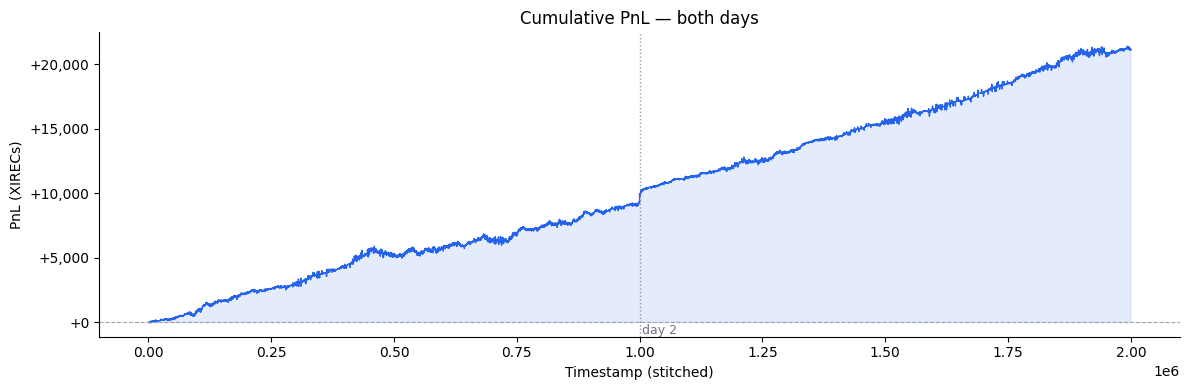

In [11]:
def stitch_curve(pnl_curve):
    xs, ys, offset, prev_max = [], [], 0, 0
    for i, (ts, pnl) in enumerate(pnl_curve):
        if i > 0 and ts < pnl_curve[i-1][0]:
            offset += prev_max + 100
        xs.append(ts + offset)
        ys.append(pnl)
        prev_max = max(prev_max, ts)
    return xs, ys

if HAS_MPL:
    xs, ys = stitch_curve(r["pnl_curve"])
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(xs, ys, linewidth=1, color="#2563eb")
    ax.axhline(0, color="#9ca3af", linewidth=0.8, linestyle="--")
    ax.fill_between(xs, ys, 0, where=[p >= 0 for p in ys], alpha=0.12, color="#2563eb")
    ax.fill_between(xs, ys, 0, where=[p <  0 for p in ys], alpha=0.12, color="#dc2626")
    for i, (ts, _) in enumerate(r["pnl_curve"]):
        if i > 0 and ts < r["pnl_curve"][i-1][0]:
            ax.axvline(xs[i], color="#6b7280", linewidth=1, linestyle=":", alpha=0.7)
            ax.text(xs[i] + 5000, ax.get_ylim()[0],
                    "day 2", fontsize=9, color="#6b7280", va="bottom")
    import matplotlib.ticker as mtick
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f"{x:+,.0f}"))
    ax.set_xlabel("Timestamp (stitched)")
    ax.set_ylabel("PnL (XIRECs)")
    ax.set_title("Cumulative PnL — both days")
    ax.spines[["top","right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


## 12. Parameter sweep

Key levers for this strategy:
- `eSpread` — emerald half-spread (ticks inside the ±8 bot spread)
- `tSpread` — tomato base half-spread
- `eSkew` — emerald inventory skew strength
- `tFairW` — how strongly fair value follows the trend (>1 = momentum-following)
- `tExtremeZ` — z-score threshold for the mean-reversion safety valve


In [12]:
sweep = []
for e_spread in [3, 4, 5]:
    for t_spread in [4, 5, 6]:
        for e_skew in [1, 2, 4]:
            for t_fair_w in [0.8, 1.0, 1.2]:
                for t_extreme_z in [1.0, 1.5, 2.0]:
                    t = Trader()
                    t._emerald.HALF_SPREAD        = e_spread
                    t._emerald.SKEW_MAX           = e_skew
                    t._tomato.BASE_HALF_SPREAD    = t_spread
                    t._tomato.TREND_FAIR_WEIGHT   = t_fair_w
                    t._tomato.EXTREME_Z           = t_extreme_z
                    r2 = run_backtest(t)
                    sweep.append({
                        "eSpread":    e_spread,
                        "tSpread":    t_spread,
                        "eSkew":      e_skew,
                        "tFairW":     t_fair_w,
                        "tExtremeZ":  t_extreme_z,
                        "totalPnl":   r2["totalPnl"],
                        "emeraldPnl": r2["pnlByProduct"].get("EMERALDS", 0),
                        "tomatoPnl":  r2["pnlByProduct"].get("TOMATOES", 0),
                        "numTrades":  r2["numTrades"],
                        "endPositions": r2["endPositions"],
                    })

sweep.sort(key=lambda x: -x["totalPnl"])
print(f"{'eSp':>4}  {'tSp':>4}  {'eSk':>4}  {'tFW':>5}  {'tEZ':>5}  "
      f"{'total':>12}  {'emerald':>10}  {'tomato':>10}  {'posT':>6}")
print("-" * 75)
for s in sweep[:15]:
    print(f"{s['eSpread']:>4}  {s['tSpread']:>4}  {s['eSkew']:>4}  "
          f"{s['tFairW']:>5.1f}  {s['tExtremeZ']:>5.1f}  "
          f"{s['totalPnl']:>+12,.0f}  {s['emeraldPnl']:>+10,.0f}  "
          f"{s['tomatoPnl']:>+10,.0f}  "
          f"{s['endPositions'].get('TOMATOES', 0):>6}")


 eSp   tSp   eSk    tFW    tEZ         total     emerald      tomato    posT
---------------------------------------------------------------------------
   5     5     1    1.2    1.0       +23,472    +130,299    -116,996      26
   5     5     1    1.2    1.5       +23,470    +130,299    -116,998      26
   5     5     1    1.2    2.0       +23,443    +130,299    -117,025      26
   5     5     2    1.2    1.0       +23,253    +130,080    -116,996      26
   5     5     2    1.2    1.5       +23,251    +130,080    -116,998      26
   5     5     2    1.2    2.0       +23,224    +130,080    -117,025      26
   5     5     1    0.8    1.0       +22,928    +130,299    -132,560      29
   5     5     1    0.8    1.5       +22,912    +130,299    -132,576      29
   5     5     1    0.8    2.0       +22,898    +130,299    -132,589      29
   5     5     1    1.0    1.0       +22,811    +130,299     -97,631      22
   5     5     1    1.0    2.0       +22,798    +130,299     -97,644      22


## 13. Best parameter run

In [13]:
best = sweep[0]
print(f"Best parameters: {best}")
print()

bestTrader = Trader()
bestTrader._emerald.HALF_SPREAD      = best["eSpread"]
bestTrader._emerald.SKEW_MAX         = best["eSkew"]
bestTrader._tomato.BASE_HALF_SPREAD  = best["tSpread"]
bestTrader._tomato.TREND_FAIR_WEIGHT = best["tFairW"]
bestTrader._tomato.EXTREME_Z         = best["tExtremeZ"]

r_best = run_backtest(bestTrader)
print_results("── Best tuned trader ──", r_best)


Best parameters: {'eSpread': 5, 'tSpread': 5, 'eSkew': 1, 'tFairW': 1.2, 'tExtremeZ': 1.0, 'totalPnl': 23472.0, 'emeraldPnl': 130299.0, 'tomatoPnl': -116996.0, 'numTrades': 1753, 'endPositions': {'EMERALDS': -12, 'TOMATOES': 26}}

── Best tuned trader ──
  Total PnL    :      +23,472
  Realized     :      +13,303
  MTM          :      +10,169
  EMERALDS PnL :     +130,299
  TOMATOES PnL :     -116,996
  Num trades   : 1753
  End positions: {'EMERALDS': -12, 'TOMATOES': 26}

